<a href="https://colab.research.google.com/github/Chandithya/Abc/blob/main/chandithya_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

N Chandithya

Minor project 04 - Random Forest Algorithm

Dataset url:https://drive.google.com/file/d/1z3I-MdNygLKmBTR7TnMg98bwjmeJ_5am/view?usp=drive_link

https://drive.google.com/file/d/1AoRxxnW0XYX4MXjSNC6i4I54Qsw1bXGc/view?usp=drive_link

Here is the drive link of the two datasets i have used


Performing EDA on the dataset to predict the status of  credit card of the customer

In [40]:
#importing the libraries needed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [41]:
#Adding the csv files needed to the project-credit status prediction
import pandas as pd
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()

Saving application_record.csv to application_record (4).csv
Shape: (438557, 18)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [42]:
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()

Saving credit_record.csv to credit_record (4).csv
Shape: (1048575, 3)


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [43]:
# Load the datasets with correct variable names
app_df = pd.read_csv('application_record.csv')
credit_df = pd.read_csv('credit_record.csv')

# Merging the two datasets
df_read = pd.merge(app_df, credit_df, on="ID", how="inner")

print('Merged Shape:', df_read.shape)
df_read.head()

Merged Shape: (777715, 20)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,MONTHS_BALANCE,STATUS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,0,C
1,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,-1,C
2,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,-2,C
3,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,-3,C
4,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,-4,C


In [44]:
df_read.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777715 entries, 0 to 777714
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   777715 non-null  int64  
 1   CODE_GENDER          777715 non-null  object 
 2   FLAG_OWN_CAR         777715 non-null  object 
 3   FLAG_OWN_REALTY      777715 non-null  object 
 4   CNT_CHILDREN         777715 non-null  int64  
 5   AMT_INCOME_TOTAL     777715 non-null  float64
 6   NAME_INCOME_TYPE     777715 non-null  object 
 7   NAME_EDUCATION_TYPE  777715 non-null  object 
 8   NAME_FAMILY_STATUS   777715 non-null  object 
 9   NAME_HOUSING_TYPE    777715 non-null  object 
 10  DAYS_BIRTH           777715 non-null  int64  
 11  DAYS_EMPLOYED        777715 non-null  int64  
 12  FLAG_MOBIL           777715 non-null  int64  
 13  FLAG_WORK_PHONE      777715 non-null  int64  
 14  FLAG_PHONE           777715 non-null  int64  
 15  FLAG_EMAIL       

In [45]:
#checking for the null values
df_read.isnull().sum()

,0
ID,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,0
NAME_HOUSING_TYPE,0


In [46]:
#Treating the null values
df_read["OCCUPATION_TYPE"]=df_read["OCCUPATION_TYPE"].fillna(df_read["OCCUPATION_TYPE"].mode()[0])

In [47]:
#checking for the missing values
df_read.isnull().sum()

,0
ID,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,0
NAME_HOUSING_TYPE,0


In [48]:
#checking for the duplicated values
df_read.duplicated().sum()

np.int64(0)

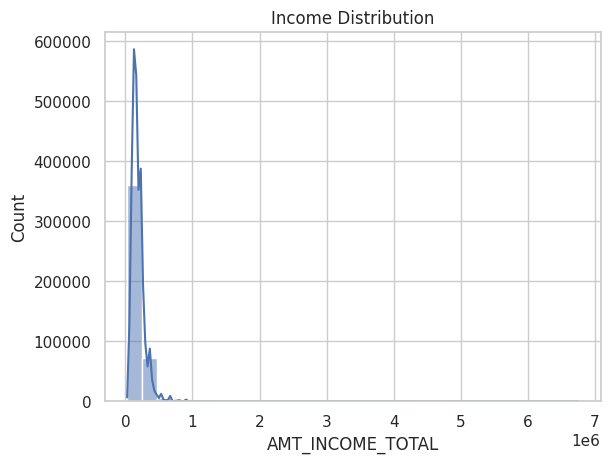

In [49]:
#univariate analysis
sns.histplot(app_df["AMT_INCOME_TOTAL"], bins=30, kde=True)
plt.title("Income Distribution")
plt.show()

In the income distribution we observe that annual income of the customers is between 300000 to 400000 but there are few outliers in the above graph as we can see few people have very less and few with more annual income

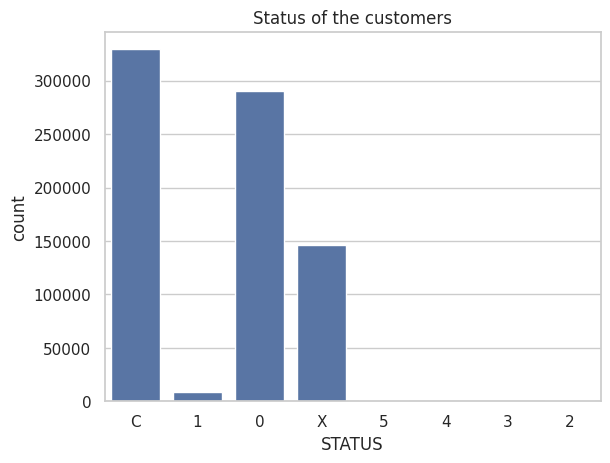

In [50]:
#for cattegorical values
sns.countplot(x=df_read["STATUS"])
plt.title("Status of the customers")
plt.show()

from the above graph we observe that ccolumns C has more count which means that over 320000 people had been paid off there debt whereas over 10000 people are 30_59 days past overdue etc

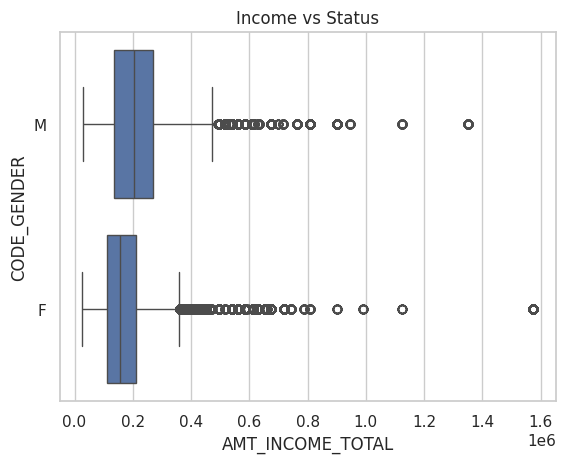

In [51]:
#Bivariate analysis using the merged dataset
sns.boxplot(x = 'AMT_INCOME_TOTAL', y = 'CODE_GENDER', data = df_read)
plt.title("Income vs Status")
plt.show()

From the above graphh we observe that there is no much difference in the income of both men and women therefore gender does not affects the annual income much.

But we can see there are many ouliers in both  the genders.

In [52]:
#converting the categorical to numerical values using binary conversion
df_read["CODE_GENDER"] = df_read["CODE_GENDER"].map({"M": 0, "F": 1})
df_read["FLAG_OWN_CAR"] = df_read["FLAG_OWN_CAR"].map({"N": 0, "Y": 1})
df_read["FLAG_OWN_REALTY"] = df_read["FLAG_OWN_REALTY"].map({"N": 0, "Y": 1})

# Fill NaN if any unexpected values remain
df_read[["CODE_GENDER","FLAG_OWN_CAR","FLAG_OWN_REALTY"]] = df_read[["CODE_GENDER","FLAG_OWN_CAR","FLAG_OWN_REALTY"]].fillna(-1)

print(df_read[["CODE_GENDER","FLAG_OWN_CAR","FLAG_OWN_REALTY"]].head())

   CODE_GENDER  FLAG_OWN_CAR  FLAG_OWN_REALTY
0            0             1                1
1            0             1                1
2            0             1                1
3            0             1                1
4            0             1                1


In [53]:
df_read.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777715 entries, 0 to 777714
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   777715 non-null  int64  
 1   CODE_GENDER          777715 non-null  int64  
 2   FLAG_OWN_CAR         777715 non-null  int64  
 3   FLAG_OWN_REALTY      777715 non-null  int64  
 4   CNT_CHILDREN         777715 non-null  int64  
 5   AMT_INCOME_TOTAL     777715 non-null  float64
 6   NAME_INCOME_TYPE     777715 non-null  object 
 7   NAME_EDUCATION_TYPE  777715 non-null  object 
 8   NAME_FAMILY_STATUS   777715 non-null  object 
 9   NAME_HOUSING_TYPE    777715 non-null  object 
 10  DAYS_BIRTH           777715 non-null  int64  
 11  DAYS_EMPLOYED        777715 non-null  int64  
 12  FLAG_MOBIL           777715 non-null  int64  
 13  FLAG_WORK_PHONE      777715 non-null  int64  
 14  FLAG_PHONE           777715 non-null  int64  
 15  FLAG_EMAIL       

In [54]:
#using label encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df_read.select_dtypes(include='object').columns:
    df_read[col] = le.fit_transform(df_read[col].astype(str))

In [55]:
df_read.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777715 entries, 0 to 777714
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   777715 non-null  int64  
 1   CODE_GENDER          777715 non-null  int64  
 2   FLAG_OWN_CAR         777715 non-null  int64  
 3   FLAG_OWN_REALTY      777715 non-null  int64  
 4   CNT_CHILDREN         777715 non-null  int64  
 5   AMT_INCOME_TOTAL     777715 non-null  float64
 6   NAME_INCOME_TYPE     777715 non-null  int64  
 7   NAME_EDUCATION_TYPE  777715 non-null  int64  
 8   NAME_FAMILY_STATUS   777715 non-null  int64  
 9   NAME_HOUSING_TYPE    777715 non-null  int64  
 10  DAYS_BIRTH           777715 non-null  int64  
 11  DAYS_EMPLOYED        777715 non-null  int64  
 12  FLAG_MOBIL           777715 non-null  int64  
 13  FLAG_WORK_PHONE      777715 non-null  int64  
 14  FLAG_PHONE           777715 non-null  int64  
 15  FLAG_EMAIL       

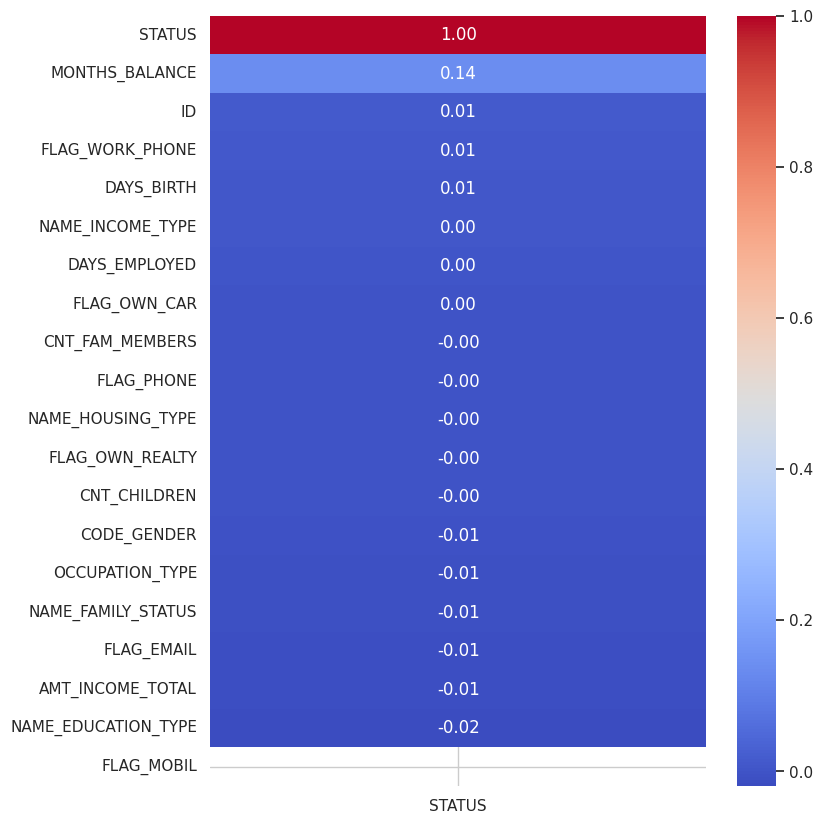

In [56]:
status_corr=df_read.corr()
status_target_corr= status_corr["STATUS"].sort_values(ascending = False)
plt.figure(figsize =(8,10))
sns.heatmap(status_target_corr.to_frame(), annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.show()

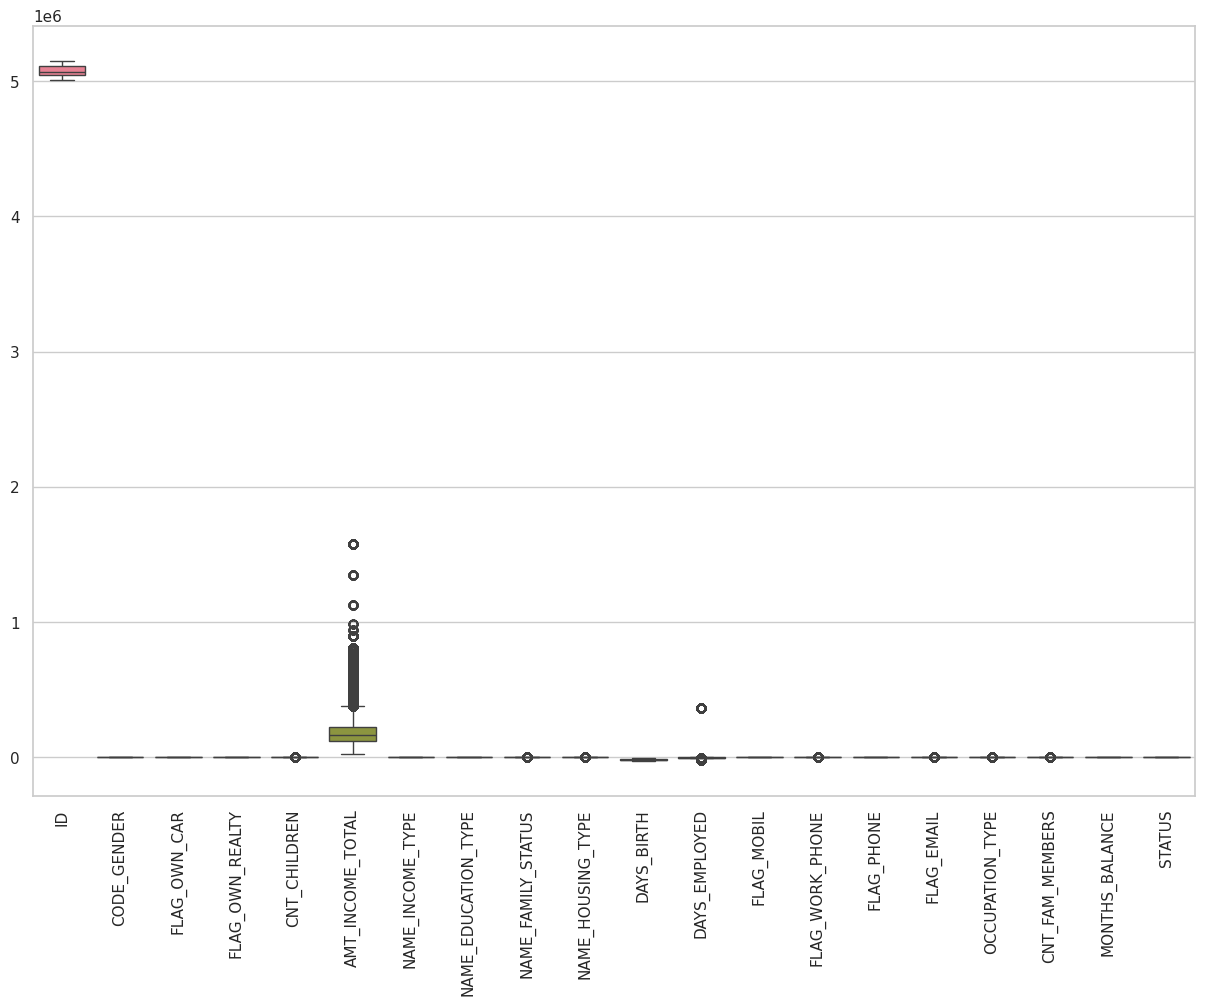

In [57]:
#checking for the outliers
plt.figure(figsize = (15,10))
sns.boxplot(data = df_read.select_dtypes(include = 'number'))
plt.xticks(rotation = 90)
plt.show()

In [58]:
#Count of the outliers
for col in df_read.select_dtypes(include = 'number').columns:
  Q1 = df_read[col].quantile(0.25)
  Q3 = df_read[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  outliers = df_read[(df_read[col] < lower_bound) | (df_read[col] > upper_bound)]
  print(f"Outliers in {col}:{len(outliers)}")

Outliers in ID:0
Outliers in CODE_GENDER:0
Outliers in FLAG_OWN_CAR:0
Outliers in FLAG_OWN_REALTY:0
Outliers in CNT_CHILDREN:11039
Outliers in AMT_INCOME_TOTAL:33987
Outliers in NAME_INCOME_TYPE:0
Outliers in NAME_EDUCATION_TYPE:0
Outliers in NAME_FAMILY_STATUS:231096
Outliers in NAME_HOUSING_TYPE:80564
Outliers in DAYS_BIRTH:0
Outliers in DAYS_EMPLOYED:163348
Outliers in FLAG_MOBIL:0
Outliers in FLAG_WORK_PHONE:180288
Outliers in FLAG_PHONE:0
Outliers in FLAG_EMAIL:71297
Outliers in OCCUPATION_TYPE:127090
Outliers in CNT_FAM_MEMBERS:10631
Outliers in MONTHS_BALANCE:0
Outliers in STATUS:0


In [59]:
#Treating the outliers
df_clean = df_read.copy()
columns = ['CNT_CHILDREN','AMT_INCOME_TOTAL','NAME_FAMILY_STATUS','NAME_HOUSING_TYPE','DAYS_EMPLOYED','FLAG_WORK_PHONE','FLAG_EMAIL','OCCUPATION_TYPE','CNT_FAM_MEMBERS']
for i in columns:
  Q1 = df_clean[i].quantile(0.25)
  Q3 = df_clean[i].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  df_clean = df_clean[(df_clean[i] >= lower_bound) & (df_clean[i] <= upper_bound)]

Linear regression : splitting the data into X and y

In [60]:
#Data Imbalance
df_clean["STATUS"].value_counts()

,count
STATUS,
6,139129
0,122206
7,61725
1,3715
5,710
2,291
3,98
4,80


In [61]:
df_clean["STATUS"].value_counts(normalize= True)*100

,proportion
STATUS,
6,42.423328
0,37.263153
7,18.821237
1,1.132781
5,0.216494
2,0.088732
3,0.029882
4,0.024394


In [62]:
#splitting the data
from sklearn.model_selection import train_test_split
X = df_clean.drop("STATUS", axis = 1)
y = df_clean["STATUS"]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state = 42)

In [63]:
#Balancing the data using smote technique
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [64]:
#Checking the data is balanced
print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: STATUS
6    111249
0     97656
7     49496
1      2994
5       587
2       242
3        78
4        61
Name: count, dtype: int64
After SMOTE: STATUS
6    111249
7    111249
0    111249
1    111249
2    111249
5    111249
4    111249
3    111249
Name: count, dtype: int64


Using random forest classifier algorithm since the output expected is a categorical column which is STATUS

the Hyperparameters used is n_estimaters : To control the trees are built

max_depth : is used to know how deep a tree can grow

In [65]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 10,
    min_samples_split=5,    # avoid too many splits
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train_smote, y_train_smote)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5, n_jobs=-1,
                       random_state=42)

In [66]:
#Training the model to to predictions
y_train_pred = model.predict(X_train_smote)
y_test_pred = model.predict(X_test)

In [67]:
#Testing the accuracy of the predicting  model
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train_pred, y_train_smote))
print(accuracy_score(y_test_pred, y_test))

0.6972658181197134
0.5494808739003827


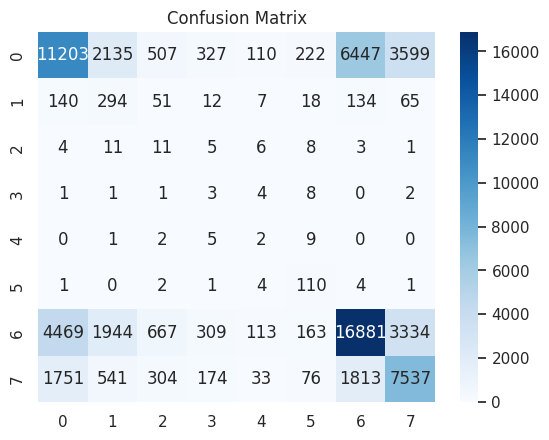

In [68]:
#confusion matrix
from sklearn.metrics import confusion_matrix
y_test_pred = model.predict(X_test)

# Compute the confusion matrix first
conf_matrix = confusion_matrix(y_test, y_test_pred)

sns.heatmap(conf_matrix, annot = True, fmt = "d", cmap = "Blues")
plt.title("Confusion Matrix")
plt.show()

In [69]:
#classification report
from sklearn.metrics import classification_report
print(classification_report(y_train_pred, y_train_smote))
print(classification_report(y_test_pred, y_test))

              precision    recall  f1-score   support

           0       0.47      0.57      0.52     91918
           1       0.67      0.76      0.71     97866
           2       0.78      0.82      0.80    106157
           3       0.66      0.68      0.67    107886
           4       0.83      0.67      0.74    137647
           5       0.93      0.84      0.88    122244
           6       0.62      0.55      0.58    124764
           7       0.62      0.68      0.65    101510

    accuracy                           0.70    889992
   macro avg       0.70      0.70      0.69    889992
weighted avg       0.71      0.70      0.70    889992

              precision    recall  f1-score   support

           0       0.46      0.64      0.53     17569
           1       0.41      0.06      0.10      4927
           2       0.22      0.01      0.01      1545
           3       0.15      0.00      0.01       836
           4       0.11      0.01      0.01       279
           5       0.89 

KEY OBSERVATIONS


*   accuracy or precision is around 55% which the model predicts 50% of the data correctly
*   around 65% of the data is supported by the model



In [70]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the base estimator and parameters
rf = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced')
param_grid = {
    'max_depth': [5, 10],
    'n_estimators': [50, 100]
}

# Exhaustive search using grid search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1_macro',   # or 'accuracy', 'recall', etc.
    cv=5,                 # 5-fold cross-validation
    n_jobs=-1             # use all CPU cores
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Best Score: 0.30177390262773984


In [73]:
#model evaluation
best_model = grid_search.best_estimator_
y_train_pred = best_model.predict(X_train_smote)
y_test_pred = best_model.predict(X_test)
print(accuracy_score(y_train_pred, y_train_smote))
print(accuracy_score(y_test_pred, y_test))

0.5056449945617488
0.5768931713192359


Training accuracy (70%) vs Test accuracy (55%) → The model is overfitting to training data and failing to generalize.

Minority classes (1–5) → Very poor recall and F1, meaning defaults or rare statuses are not being detected.

GridSearchCV best score (0.30 f1_macro) → Confirms imbalance is the main issue; macro F1 is low because rare classes are ignored.

Overall accuracy ~55% → Misleading, since majority classes dominate.

WHY WE HAVE SKIPPED STANDARDSCALER?

We skip StandardScaler for RandomForest because scaling doesn’t affect tree-based models.

It saves computation time and avoids unnecessary preprocessing.

Scaling is only essential for models sensitive to feature magnitude (distance-based or gradient-based).